In [2]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np

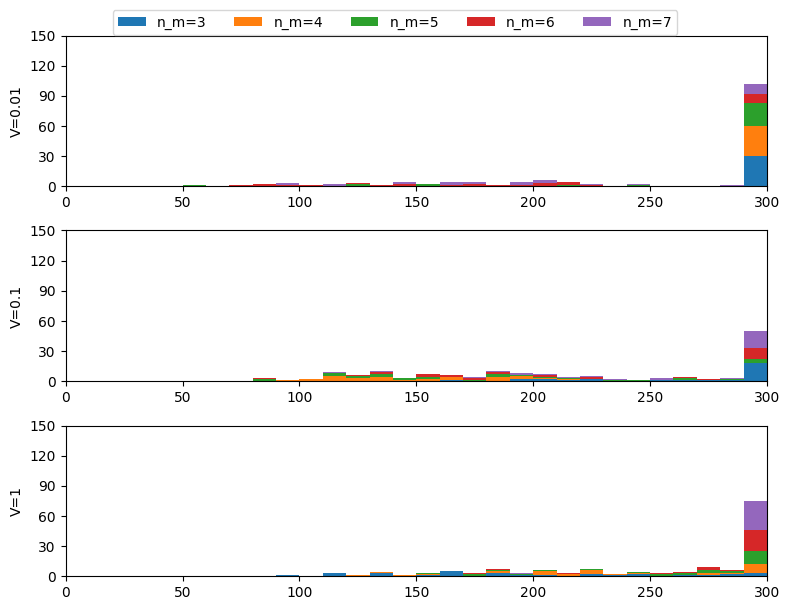

In [3]:
Vs = [0.01, 0.1, 1]
fig, axes = plt.subplots(len(Vs), 1, figsize=(8, 2*len(Vs)))
machines = range(3, 8)
for V, ax in zip(Vs, axes):
    all_latest = list()
    for n_m in machines:
        latest = list()
        for id in range(30):
            path = f'results_new/Whisper3/Li2024-WithoutCapacityConstraints-V={V}/n_m={n_m}-max_d=1000/C_avg=0.025-R_avg=2/id={id}'
            if os.path.exists(path): l = os.listdir(path)
            else: l = list()
            if 'config.json' in l: l.remove('config.json')
            l = [int(x.split('=')[1].split('.')[0]) for x in l]
            if l: latest.append(max(l))
            else: latest.append(0)
            # if max(l) != 299: print(path, max(l))
        all_latest.append(latest)
    ax.hist(all_latest, bins=range(0, 301, 10), label=[f'n_m={n_m}' for n_m in machines] if V == Vs[0] else None, histtype='barstacked')
    ax.set_xlim((0, 300))
    ax.set_yticks(range(0, 151, 30))
    # ax.set_yscale('log')
    ax.set_ylabel(f'V={V}')
fig.legend(ncols=5, loc='upper center', bbox_to_anchor=(.5, 1.02))
fig.tight_layout()
plt.show()
plt.close()

In [ ]:
Vs = [0.01, 0.1, 1, 10, 100]
fig, axes = plt.subplots(1, len(Vs), figsize=(3*len(Vs), 3))
for V, ax in zip(Vs, axes):
    machines = range(3, 8)
    NotRun = Optimal = TimeLimit = 0
    for n_m in machines:
        counter = dict()
        for id in range(30):
            path = f'results_new/Whisper3/Li2024-WithoutCapacityConstraints-V={V}/n_m={n_m}-max_d=1000/C_avg=0.025-R_avg=2/id={id}'
            l = os.listdir(path)
            if 'config.json' in l:
                l.remove('config.json')
            for x in l:
                with open(f'{path}/{x}', 'r') as f:
                    data = json.load(f)
                counter[data['status']] = counter.get(data['status'], 0) + 1
        ax.bar(
            ['NotRun', 'Optimal', 'TimeLimit'], 
            [counter.get('NotRun', 0), counter.get('Optimal', 0), counter.get('TimeLimit', 0)], 
            bottom=[NotRun, Optimal, TimeLimit],
            label=f'n_m={n_m}' if V == Vs[0] else None, # alpha=0.5
        )
        NotRun += counter.get('NotRun', 0)
        Optimal += counter.get('Optimal', 0)
        TimeLimit += counter.get('TimeLimit', 0)
    # ax.set_xlim((0, 300))
    # ax.set_yticks(range(0, 151, 30))
    # ax.set_yscale('log')
    ax.set_ylabel(f'V={V}')
fig.legend(ncols=5, loc='upper center', bbox_to_anchor=(.5, 1.05))
fig.tight_layout()
plt.show()
plt.close()